# Modulo 1 – Il neurone e il classificatore lineare

*Dal neurone al transformer · un percorso in Python per capire come funzionano davvero le reti neurali*

In questo primo modulo costruiamo il mattone più semplice di ogni rete neurale: **un singolo neurone artificiale**. Lo useremo come classificatore, cioè per decidere a quale di due gruppi appartiene un punto.

**Alla fine del modulo saprai:**
- scrivere il neurone come funzione di punteggio $z = \mathbf{w} \cdot \mathbf{x} + b$;
- distinguere tra **funzione di punteggio** e **confine di decisione**, e vederli entrambi;
- leggere la geometria del classificatore: che ruolo hanno $\mathbf{w}$ e $b$;
- addestrare un **percettrone** con la regola di Rosenblatt;
- riconoscere il suo limite fondamentale, il problema XOR, che ci porterà al Modulo 3.

In [1]:
# Su Google Colab scarichiamo il repository, così gli esercizi e i test sono disponibili
import sys, os
if "google.colab" in sys.modules and not os.path.exists("esercizi.py"):
    !git clone -q https://github.com/robermanni/dal-neurone-al-transformer.git
    %cd dal-neurone-al-transformer/moduli/01_neurone

/content/dal-neurone-al-transformer/moduli/01_neurone


In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
plt.rcParams["figure.dpi"] = 110

## 1. Il neurone come funzione di punteggio

Un neurone artificiale riceve un vettore di input $\mathbf{x} = (x_1, x_2, \dots, x_n)$, moltiplica ogni componente per un **peso**, somma tutto e aggiunge un **bias**:

$$z = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b = \mathbf{w} \cdot \mathbf{x} + b$$

Il numero $z$ è il **punteggio**. Per classificare basta guardarne il segno:

$$\hat{y} = \begin{cases} +1 & \text{se } z \ge 0 \\ -1 & \text{se } z < 0 \end{cases}$$

È tutto qui: un prodotto scalare, una somma e un controllo del segno. Tutta la complessità delle reti neurali nasce dal combinare molti di questi pezzi.

In [3]:
def punteggio(X, w, b):
    # X ha forma (n_punti, n_caratteristiche): calcoliamo z per tutti i punti in un colpo
    return X @ w + b

def predici(X, w, b):
    return np.where(punteggio(X, w, b) >= 0, 1, -1)

w = np.array([1.0, 2.0])
b = -1.0
X_prova = np.array([[1.0, 1.0], [0.0, 0.0], [-1.0, 0.5]])
print("punteggi:", punteggio(X_prova, w, b))
print("classi:  ", predici(X_prova, w, b))

punteggi: [ 2. -1. -1.]
classi:   [ 1 -1 -1]


## 2. Un dataset da classificare

Generiamo due nuvole di punti nel piano: la classe $+1$ (blu) e la classe $-1$ (arancione). Il piano ci permette di *vedere* tutto quello che succede, e le stesse idee valgono identiche in 1000 dimensioni.

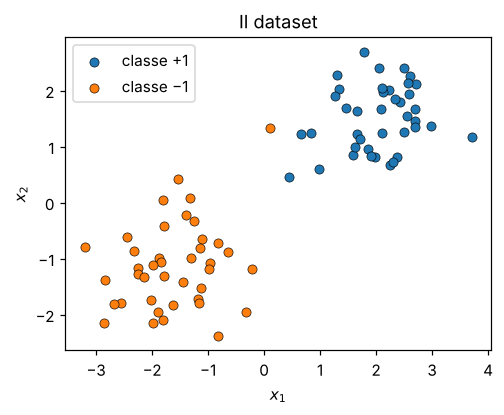

In [ ]:
n = 40
X = np.vstack([rng.normal([2.0, 1.5], 0.8, size=(n, 2)),
               rng.normal([-1.5, -1.0], 0.8, size=(n, 2))])
y = np.array([1] * n + [-1] * n)

def disegna_dati(ax, X, y):
    ax.scatter(*X[y == 1].T, c="tab:blue", label="classe +1", edgecolor="k", lw=0.4)
    ax.scatter(*X[y == -1].T, c="tab:orange", label="classe −1", edgecolor="k", lw=0.4)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")

fig, ax = plt.subplots(figsize=(5, 5))
disegna_dati(ax, X, y); ax.legend(); ax.set_title("Il dataset")
plt.show()

## 3. Punteggio e confine: due oggetti diversi

Qui c'è una distinzione che molti corsi saltano, e che invece chiarisce tutto.

- La **funzione di punteggio** $z(x_1, x_2) = w_1 x_1 + w_2 x_2 + b$ assegna un numero a *ogni* punto del piano. Il suo grafico è un **piano inclinato** nello spazio a tre dimensioni.
- Il **confine di decisione** è l'insieme dei punti dove $z = 0$. È l'intersezione di quel piano inclinato con il "pavimento": in 2D è una **retta**, in generale un **iperpiano**.

Il classificatore usa il punteggio solo per il segno, ma il punteggio contiene più informazione: quanto un punto è "convintamente" da una parte o dall'altra.

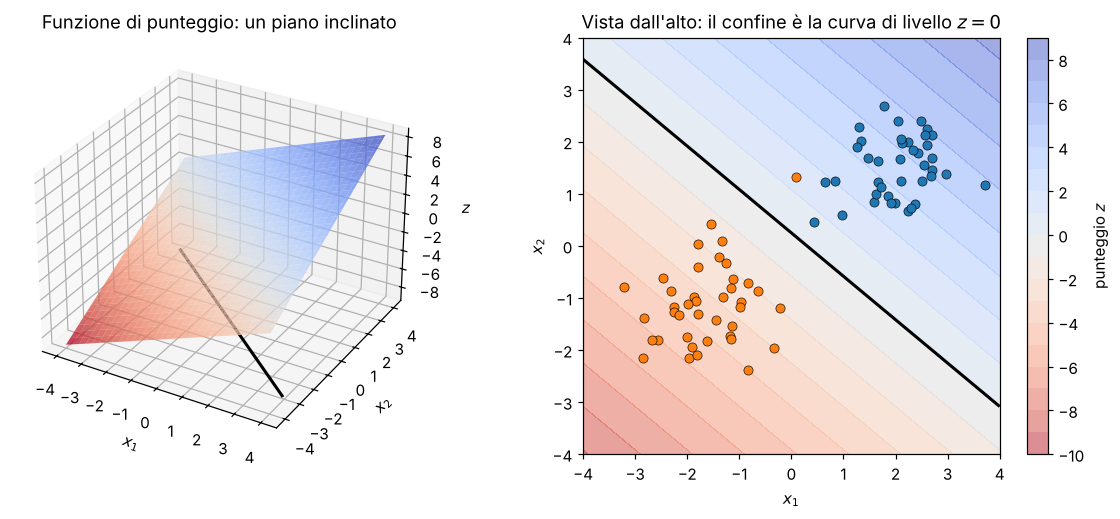

In [ ]:
w = np.array([1.0, 1.2]); b = -0.3   # un classificatore scelto a mano, per ora

g = np.linspace(-4, 4, 60)
G1, G2 = np.meshgrid(g, g)
Z = w[0] * G1 + w[1] * G2 + b

fig = plt.figure(figsize=(11, 4.6))
ax3d = fig.add_subplot(1, 2, 1, projection="3d")
ax3d.plot_surface(G1, G2, Z, cmap="coolwarm_r", alpha=0.75, linewidth=0)
ax3d.contour(G1, G2, Z, levels=[0], colors="k", linewidths=2, offset=Z.min())
ax3d.set_xlabel("$x_1$"); ax3d.set_ylabel("$x_2$"); ax3d.set_zlabel("$z$")
ax3d.set_title("Funzione di punteggio: un piano inclinato")

ax = fig.add_subplot(1, 2, 2)
cf = ax.contourf(G1, G2, Z, levels=20, cmap="coolwarm_r", alpha=0.5)
ax.contour(G1, G2, Z, levels=[0], colors="k", linewidths=2)
disegna_dati(ax, X, y)
fig.colorbar(cf, ax=ax, label="punteggio $z$")
ax.set_title("Vista dall'alto: il confine è la curva di livello $z = 0$")
plt.tight_layout(); plt.show()

## 4. La geometria di $\mathbf{w}$ e $b$

Tre fatti da tenere a mente, perché ritorneranno in tutto il percorso:

1. **$\mathbf{w}$ è perpendicolare al confine** e punta verso la regione positiva. È la direzione in cui il punteggio cresce più in fretta: il *gradiente* di $z$ rispetto a $\mathbf{x}$ è proprio $\mathbf{w}$.
2. **$b$ sposta il confine** parallelamente a se stesso, senza ruotarlo.
3. **La distanza di un punto dal confine** è il punteggio diviso per la lunghezza di $\mathbf{w}$:
$$d(\mathbf{x}) = \frac{\mathbf{w} \cdot \mathbf{x} + b}{\lVert \mathbf{w} \rVert}$$
Per questo se moltiplichi $\mathbf{w}$ e $b$ per 10 il confine non cambia: cambiano solo i punteggi. Lo implementerai tu negli esercizi.

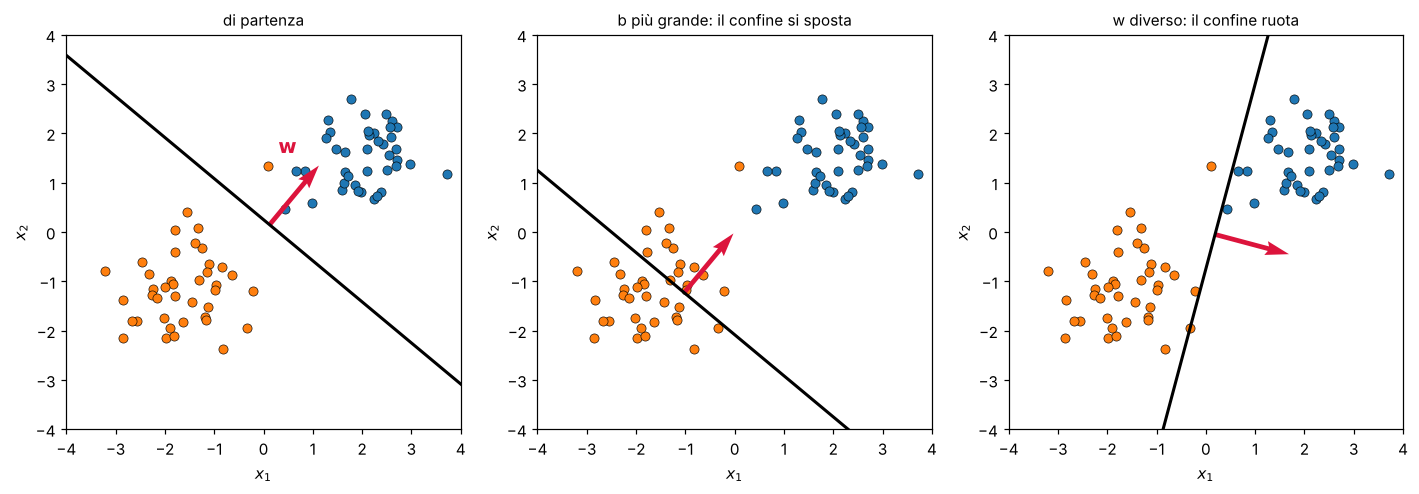

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
casi = [(np.array([1.0, 1.2]), -0.3, "di partenza"),
        (np.array([1.0, 1.2]), 2.5, "b più grande: il confine si sposta"),
        (np.array([1.5, -0.4]), -0.3, "w diverso: il confine ruota")]
xs = np.linspace(-4, 4, 2)
for ax, (w_, b_, titolo) in zip(axes, casi):
    disegna_dati(ax, X, y)
    ax.plot(xs, -(w_[0] * xs + b_) / w_[1], "k", lw=2)
    p0 = -b_ * w_ / (w_ @ w_)            # punto del confine più vicino all'origine
    ax.quiver(*p0, *w_, angles="xy", scale_units="xy", scale=1, color="crimson", width=0.012)
    ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_title(titolo, fontsize=10)
axes[0].text(0.3, 1.6, "$\\mathbf{w}$", color="crimson", fontsize=13)
plt.tight_layout(); plt.show()

## 5. Imparare dai dati: il percettrone

Finora i pesi li abbiamo scelti noi. L'idea rivoluzionaria di Frank Rosenblatt (1958) è farli **imparare dagli errori**.

Partiamo da $\mathbf{w} = \mathbf{0}$, $b = 0$ e scorriamo i punti. Un punto $(\mathbf{x}_i, y_i)$ è classificato male quando $y_i \, z_i \le 0$ (il segno del punteggio non coincide con l'etichetta). In quel caso:

$$\mathbf{w} \leftarrow \mathbf{w} + y_i \, \mathbf{x}_i \qquad b \leftarrow b + y_i$$

**Perché funziona?** Dopo l'aggiornamento, il punteggio di quel punto cambia di $y_i(\lVert \mathbf{x}_i \rVert^2 + 1)$: si sposta sempre nella direzione giusta. Geometricamente, $\mathbf{w}$ ruota verso i punti positivi sbagliati e si allontana da quelli negativi sbagliati.

Il **teorema di convergenza del percettrone** garantisce che, se esiste una retta che separa perfettamente le due classi, l'algoritmo la trova in un numero finito di passi.

In [ ]:
def addestra(X, y, max_epoche=20):
    w, b = np.zeros(X.shape[1]), 0.0
    storia = [(w.copy(), b)]      # pesi alla fine di ogni epoca
    traccia = []                  # pesi dopo ogni singolo aggiornamento
    errori = []
    for _ in range(max_epoche):
        n_err = 0
        for xi, yi in zip(X, y):
            if yi * (xi @ w + b) <= 0:          # punto classificato male
                w, b = w + yi * xi, b + yi       # regola di Rosenblatt
                traccia.append((w.copy(), b))
                n_err += 1
        storia.append((w.copy(), b)); errori.append(n_err)
        if n_err == 0:                           # un'epoca senza errori: abbiamo finito
            break
    return w, b, errori, storia, traccia

# Mescoliamo l'ordine dei punti, altrimenti vedrebbe prima tutti i blu e poi tutti gli arancioni
ordine = rng.permutation(len(X))
w_fin, b_fin, errori, storia, _ = addestra(X[ordine], y[ordine])
print(f"Convergenza in {len(errori)} epoche. Errori per epoca: {errori}")
print(f"w = {w_fin},  b = {b_fin}")

Convergenza in 5 epoche. Errori per epoca: [2, 2, 2, 2, 0]
w = [ 3.50392917 -0.25873233],  b = 0.0


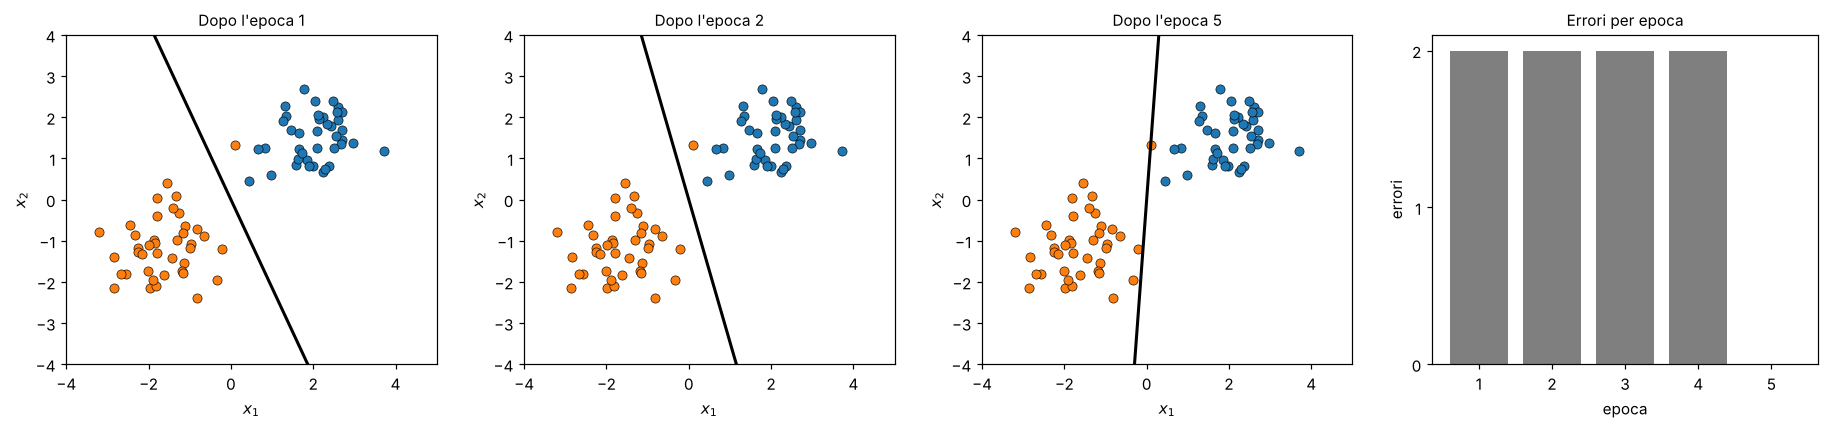

In [ ]:
from matplotlib.ticker import MaxNLocator
ultima = len(storia) - 1
passi = sorted(set([1, max(1, ultima // 2), ultima]))
fig, axes = plt.subplots(1, len(passi) + 1, figsize=(4.2 * (len(passi) + 1), 4))
for ax, e in zip(axes, passi):
    w_, b_ = storia[e]
    disegna_dati(ax, X, y)
    if w_[1] != 0:
        ax.plot(xs, -(w_[0] * xs + b_) / w_[1], "k", lw=2)
    ax.set_xlim(-4, 5); ax.set_ylim(-4, 4); ax.set_title(f"Dopo l'epoca {e}", fontsize=10)
axes[-1].bar(range(1, len(errori) + 1), errori, color="tab:gray")
axes[-1].yaxis.set_major_locator(MaxNLocator(integer=True))
axes[-1].set_xlabel("epoca"); axes[-1].set_ylabel("errori"); axes[-1].set_title("Errori per epoca", fontsize=10)
plt.tight_layout(); plt.show()

## 6. Il limite: il problema XOR

Proviamo ora con quattro punti soltanto, disposti come la funzione logica **XOR** (*o esclusivo*): l'uscita è $+1$ quando esattamente uno dei due input vale 1.

| $x_1$ | $x_2$ | XOR |
|:-:|:-:|:-:|
| 0 | 0 | −1 |
| 0 | 1 | +1 |
| 1 | 0 | +1 |
| 1 | 1 | −1 |

Prova a immaginare una retta che lasci da una parte i due punti blu e dall'altra i due arancioni: non esiste. I dati **non sono linearmente separabili**, e il percettrone non smetterà mai di sbagliare.

Errori per epoca: [4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
Pesi alla fine delle prime 3 epoche: [([0.0, 0.0], 0.0), ([0.0, 0.0], 0.0), ([0.0, 0.0], 0.0)]


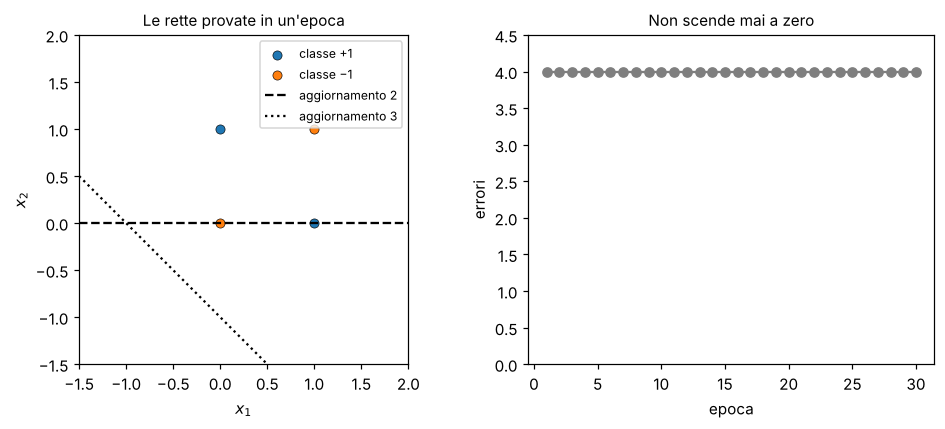

In [ ]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([-1, 1, 1, -1])
_, _, err_xor, storia_xor, traccia_xor = addestra(X_xor, y_xor, max_epoche=30)
print("Errori per epoca:", err_xor)
print("Pesi alla fine delle prime 3 epoche:", [(w_.tolist(), float(b_)) for w_, b_ in storia_xor[1:4]])

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
disegna_dati(axes[0], X_xor, y_xor)
xx = np.linspace(-1.5, 2, 2)
stili = ["-", "--", ":", "-."]
for passo, ((w_, b_), st) in enumerate(zip(traccia_xor[:4], stili), start=1):   # una singola epoca
    if w_[1] != 0:
        axes[0].plot(xx, -(w_[0] * xx + b_) / w_[1], "k", ls=st, label=f"aggiornamento {passo}")
    elif w_[0] != 0:
        axes[0].axvline(-b_ / w_[0], color="k", ls=st, label=f"aggiornamento {passo}")
axes[0].set_xlim(-1.5, 2); axes[0].set_ylim(-1.5, 2); axes[0].legend(fontsize=8, loc="upper right")
axes[0].set_title("Le rette provate in un'epoca", fontsize=10)
axes[1].plot(range(1, len(err_xor) + 1), err_xor, "o-", color="tab:gray")
axes[1].set_ylim(0, 4.5); axes[1].set_xlabel("epoca"); axes[1].set_ylabel("errori")
axes[1].set_title("Non scende mai a zero", fontsize=10)
plt.tight_layout(); plt.show()

Guarda i pesi stampati: alla fine di ogni epoca il percettrone torna **esattamente** a $\mathbf{w} = \mathbf{0}$, $b = 0$. Le quattro correzioni si annullano a vicenda e l'algoritmo gira in tondo per sempre: ogni retta che sistema un punto ne rovina un altro.

Questo risultato, reso celebre da Minsky e Papert nel 1969, frenò la ricerca sulle reti neurali per anni. La soluzione, come vedremo nel **Modulo 3**, è mettere più neuroni in fila: uno strato nascosto trasforma lo spazio in modo che i dati diventino separabili. Ma per addestrare più strati serve uno strumento nuovo, la **discesa del gradiente**, che è l'argomento del **Modulo 2**.

## 7. Esercizi

Apri il file `esercizi.py` in questa cartella e completa le quattro funzioni:

1. **`distanza_firmata`** – la distanza con segno di ogni punto dal confine.
2. **`margine`** – quanto è lontano dal confine il punto più a rischio.
3. **`addestra_percettrone`** – la tua versione dell'algoritmo, con arresto anticipato.
4. **`confine_retta`** – le coordinate della retta di confine, utili per i grafici.

Ogni funzione ha una descrizione e un esempio. Quando pensi di aver finito, lancia la cella qui sotto: i test ti diranno cosa funziona e cosa no. Le soluzioni sono in `soluzioni.py`, ma guardale solo dopo averci provato davvero.

**Domanda per riflettere:** il percettrone si ferma alla *prima* retta che separa i dati, non alla migliore. Usando la tua funzione `margine`, come potresti confrontare due rette che separano entrambe perfettamente?

In [ ]:
# Verifica le tue soluzioni (dalla cartella del modulo)
!python -m pytest test_esercizi.py --studente -q

## Riepilogo

- Un neurone calcola un **punteggio** $z = \mathbf{w}\cdot\mathbf{x} + b$ e classifica in base al segno.
- Il **punteggio** è una funzione su tutto lo spazio (un piano inclinato); il **confine** è solo il luogo dove vale zero (un iperpiano).
- $\mathbf{w}$ è perpendicolare al confine, $b$ lo trasla, e $z / \lVert\mathbf{w}\rVert$ è la distanza dal confine.
- Il **percettrone** impara correggendosi sugli errori e converge se i dati sono linearmente separabili.
- Con dati come **XOR** un singolo neurone non basta.

**Prossimo modulo:** la discesa del gradiente, ovvero come imparare minimizzando una funzione di errore invece di correggere un punto alla volta.